# Gaussian Splatting from a single stereo pair

A complete, minimal 3D Gaussian Splatting implementation — about 120 lines of
real code — that takes **two photographs** of a scene and learns a cloud of 3D
gaussian blobs that reproduces them.

The whole idea in six steps:

| # | Step | What it gives us |
|---|------|------------------|
| 1 | Load a rectified stereo pair | two views of one scene |
| 2 | Match pixels left↔right → **disparity** | how far each pixel shifted |
| 3 | `Z = f·B/d` → **depth**, then unproject | a real 3D point cloud |
| 4 | Turn each point into a **3D gaussian** | our scene representation |
| 5 | **Differentiably render** gaussians to an image | a forward model |
| 6 | **Gradient descent** on the pixel error | the splats fit the photos |

Steps 1–3 are classical stereo vision. They give us a *starting guess*.
Steps 4–6 are gaussian splatting, which refines that guess until it actually
reproduces the images.

**Why a gaussian?** Because a 3D gaussian stays a gaussian when you project it
through a camera. That single mathematical fact is what makes this method
fast: we never trace rays or march volumes, we just draw ellipses.

## Setup

Everything runs on whatever device is available. On an AMD GPU under ROCm you
still write `"cuda"` — ROCm reuses the CUDA API surface.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import plotly.graph_objects as go
from plotly.subplots import make_subplots

torch.manual_seed(0)

# "cuda" is correct for ROCm/AMD too - ROCm reuses the CUDA API surface.
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEV.type == "cuda":
    print("device:", torch.cuda.get_device_properties(0).name)
else:
    print("device: cpu")

device: AMD Radeon 890M


/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory


## Step 1 — the stereo pair

A **rectified** stereo pair is two photographs taken by identical cameras
side by side, with the images warped so that any scene point lands on the
*same horizontal row* in both. That is the whole convenience of rectification:
matching becomes a 1-D search along a row instead of a 2-D search.

We downsample hard. This notebook is about clarity, not resolution — and every
pixel we add multiplies the work in the renderer.

image tensors: (107, 128, 3) range 0.0 - 1.0


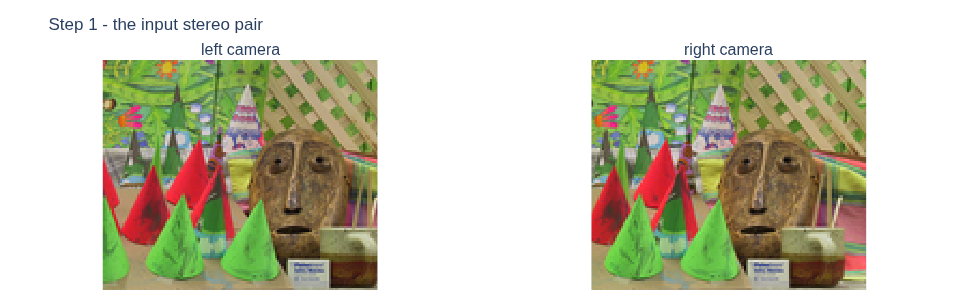

In [2]:
# Load the pair and shrink it. W and H drive the cost of everything below.
W, H = 128, 107          # 450x375 downsampled, aspect preserved

def load(path):
    im = Image.open(path).convert("RGB").resize((W, H), Image.LANCZOS)
    return torch.from_numpy(np.asarray(im, np.float32) / 255.0)   # [H,W,3] in 0..1

left  = load("data/left.png").to(DEV)
right = load("data/right.png").to(DEV)
print("image tensors:", tuple(left.shape), "range", float(left.min()), "-", float(left.max()))

def show_images(items, title, cols=None):
    '''items = [(title, HxWx3 tensor or HxW array)] -> one plotly row.'''
    cols = cols or len(items)
    fig = make_subplots(rows=1, cols=cols, subplot_titles=[t for t, _ in items],
                        horizontal_spacing=0.03)
    for i, (_, img) in enumerate(items):
        a = img.detach().cpu().numpy() if torch.is_tensor(img) else img
        if a.ndim == 3:
            fig.add_trace(go.Image(z=(np.clip(a, 0, 1) * 255).astype(np.uint8)), 1, i + 1)
        else:
            fig.add_trace(go.Heatmap(z=a[::-1], colorscale="Viridis", showscale=(i == len(items) - 1)), 1, i + 1)
    fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
    fig.update_layout(title=title, height=260 + 40, margin=dict(l=10, r=10, t=60, b=10))
    return fig

show_images([("left camera", left), ("right camera", right)],
            "Step 1 - the input stereo pair")

## Step 2 — disparity by block matching

Because the pair is rectified, the point at `(x, y)` in the **left** image
appears at `(x - d, y)` in the **right** image. That shift `d` is the
**disparity**, and it is larger for nearer objects — hold a finger up and blink
each eye in turn to see this.

To find `d` for every pixel we do the dumbest thing that works: for each
candidate shift, slide the right image across and measure how well it agrees
with the left. We compare *patches* rather than single pixels (a lone pixel is
far too ambiguous), using a box filter to sum absolute differences over a
small window. Then pick, per pixel, the shift with the lowest error.

This is "winner-take-all block matching" — the oldest stereo algorithm there
is. It is noisy and it fails on blank walls, which is exactly why step 6
exists: optimisation repairs what the initial guess gets wrong.

disparity range 0 .. 21 px


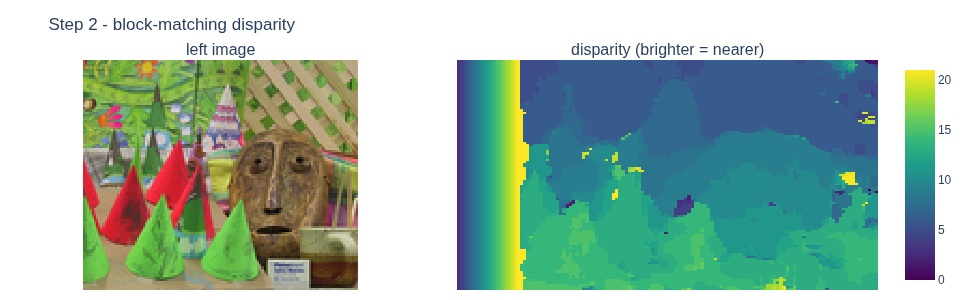

In [3]:
def block_match_disparity(imL, imR, max_disp=22, win=5):
    '''For each pixel, find the horizontal shift that best matches left->right.

    Returns a [H,W] float tensor of disparities in pixels.
    '''
    # Work in grayscale: colour adds cost without helping the match much.
    gl = imL.mean(-1)[None, None]          # [1,1,H,W]
    gr = imR.mean(-1)[None, None]
    # A box filter of ones = "sum over a window", which turns a per-pixel
    # absolute difference into a per-patch matching cost in one conv.
    box = torch.ones(1, 1, win, win, device=imL.device) / (win * win)

    costs = []
    for d in range(max_disp):
        # Shift the right image right by d, so right[x-d] lines up with left[x].
        shifted = torch.roll(gr, shifts=d, dims=3)
        if d:                                # the wrapped-around edge is garbage
            shifted[..., :d] = gl[..., :d]   # make it a no-cost match, not noise
        cost = (gl - shifted).abs()
        costs.append(F.conv2d(cost, box, padding=win // 2))
    costs = torch.cat(costs, 1)              # [1, max_disp, H, W]

    disp = costs.argmin(1).float()[0]        # winner-take-all
    conf = (costs.max(1).values - costs.min(1).values)[0]   # peak contrast
    return disp, conf

disp, conf = block_match_disparity(left, right)
print(f"disparity range {float(disp.min()):.0f} .. {float(disp.max()):.0f} px")

show_images([("left image", left), ("disparity (brighter = nearer)", disp)],
            "Step 2 - block-matching disparity")

## Step 3 — disparity to a 3D point cloud

From similar triangles, the depth of a point is

$$Z \;=\; \frac{f \cdot B}{d}$$

where `f` is focal length in pixels, `B` the distance between the two cameras
(the **baseline**), and `d` the disparity. Near things have big `d` and small
`Z`; infinitely far things have `d = 0`.

**An honest caveat.** We do not have the true calibration for this pair, so we
pick a plausible `f` and set `B = 1`. Everything below is therefore correct
*up to an overall scale factor* — the shape is right, the absolute size in
metres is arbitrary. That is a real property of uncalibrated stereo, not a
shortcut.

Unprojecting a pixel `(x, y)` at depth `Z` back into 3D is just the projection
equations rearranged:

$$X = \frac{(x - c_x)\,Z}{f}, \qquad Y = \frac{(y - c_y)\,Z}{f}, \qquad Z = Z$$

10,272 points, depth 5.49 .. 76.80


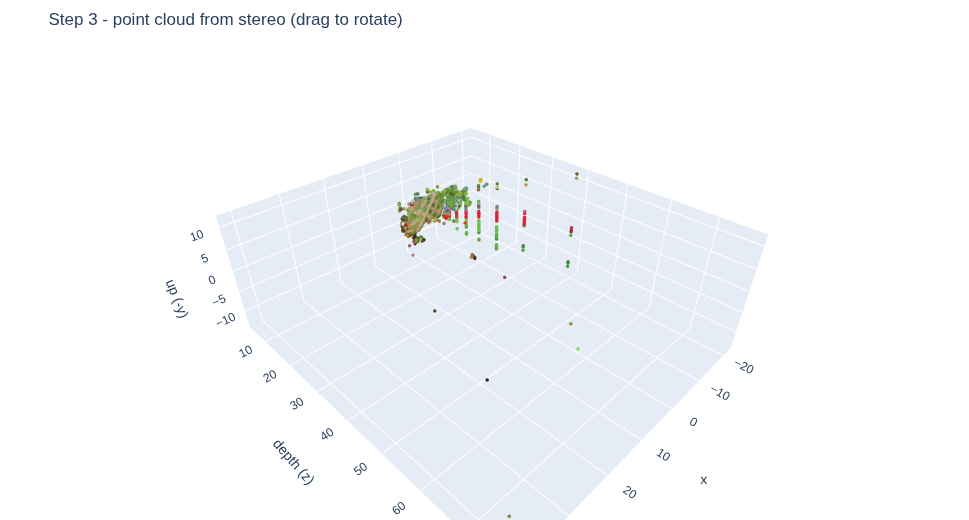

In [4]:
# Camera intrinsics. f is chosen for a sensible field of view; B sets the scale.
FX = FY = 0.9 * W
CX, CY = W / 2.0, H / 2.0
BASELINE = 1.0

# Disparity 0 means "infinitely far". Clamp it away so Z stays finite.
disp_safe = disp.clamp(min=1.5)
depth = (FX * BASELINE) / disp_safe                       # [H,W]

# Pixel grid -> 3D. Note +y points DOWN in image space, which we keep in 3D
# so that the camera convention stays consistent throughout the notebook.
ys, xs = torch.meshgrid(torch.arange(H, device=DEV, dtype=torch.float32),
                        torch.arange(W, device=DEV, dtype=torch.float32),
                        indexing="ij")
X = (xs + 0.5 - CX) * depth / FX
Y = (ys + 0.5 - CY) * depth / FY
points  = torch.stack([X, Y, depth], -1).reshape(-1, 3)   # [H*W, 3]
colours = left.reshape(-1, 3)                             # colour each point by its pixel

# Drop low-confidence matches (blank regions where block matching guesses).
keep = (conf.reshape(-1) > conf.reshape(-1).quantile(0.25))
points, colours = points[keep], colours[keep]
print(f"{points.shape[0]:,} points, depth {float(depth.min()):.2f} .. {float(depth.max()):.2f}")

def cloud_figure(pts, cols, title, size=2, n=6000):
    '''Interactive 3D scatter. Subsampled so the browser stays responsive.'''
    idx = torch.randperm(pts.shape[0])[:n]
    p = pts[idx].detach().cpu().numpy(); c = (cols[idx].detach().cpu().numpy() * 255).astype(int)
    fig = go.Figure(go.Scatter3d(
        x=p[:, 0], y=p[:, 2], z=-p[:, 1],      # plot as x / depth / up
        mode="markers",
        marker=dict(size=size, color=[f"rgb({r},{g},{b})" for r, g, b in c])))
    fig.update_layout(title=title, height=520, margin=dict(l=0, r=0, t=50, b=0),
                      scene=dict(xaxis_title="x", yaxis_title="depth (z)", zaxis_title="up (-y)",
                                 aspectmode="data"))
    return fig

cloud_figure(points, colours, "Step 3 - point cloud from stereo (drag to rotate)")

## Step 4 — from points to gaussians

Each point becomes one **3D gaussian**, described by five things:

| Parameter | Stored as | Why stored that way |
|---|---|---|
| position `μ` | 3 numbers, raw | unconstrained already |
| scale `s` | `log s` | `exp()` keeps it positive, no clamping needed |
| rotation `q` | quaternion | normalise and it is always a valid rotation |
| opacity `α` | logit | `sigmoid()` keeps it in `[0,1]` |
| colour | RGB, raw | clamped at render time |

Storing the *unconstrained* version of each parameter means the optimiser can
take any step it likes and the result is still a legal gaussian. No projection
step, no clipping — the parameterisation does the work.

Scale and rotation together form the covariance matrix

$$\Sigma = R\,S\,S^{\top}R^{\top}$$

which is what gives each blob its size, elongation and orientation in space.

In [5]:
class Gaussians:
    '''A cloud of 3D gaussians, initialised from a coloured point cloud.'''

    def __init__(self, pts, cols, n_max=7000):
        if pts.shape[0] > n_max:                     # subsample for speed
            sel = torch.randperm(pts.shape[0], device=pts.device)[:n_max]
            pts, cols = pts[sel], cols[sel]

        n = pts.shape[0]
        self.xyz = pts.clone().requires_grad_(True)

        # Start each blob roughly the size of the gap to its neighbours. Points
        # further away are sparser on screen, so scale with depth.
        init = (pts[:, 2] * 1.6 / FX).clamp(min=1e-3)
        self.log_s = torch.log(init)[:, None].repeat(1, 3).requires_grad_(True)

        q = torch.zeros(n, 4, device=pts.device); q[:, 0] = 1.0    # identity rotation
        self.quat = q.requires_grad_(True)

        # inverse_sigmoid(0.5) == 0, so start half-transparent.
        self.opacity = torch.zeros(n, 1, device=pts.device).requires_grad_(True)
        self.rgb = cols.clone().requires_grad_(True)

    def params(self):
        return [self.xyz, self.log_s, self.quat, self.opacity, self.rgb]

    def __len__(self):
        return self.xyz.shape[0]


def quat_to_rot(q):
    '''Unit quaternion [N,4] (w,x,y,z) -> rotation matrix [N,3,3].'''
    q = F.normalize(q, dim=-1)
    w, x, y, z = q.unbind(-1)
    return torch.stack([
        1 - 2 * (y * y + z * z), 2 * (x * y - w * z),     2 * (x * z + w * y),
        2 * (x * y + w * z),     1 - 2 * (x * x + z * z), 2 * (y * z - w * x),
        2 * (x * z - w * y),     2 * (y * z + w * x),     1 - 2 * (x * x + y * y),
    ], -1).reshape(-1, 3, 3)


gs = Gaussians(points, colours)
print(f"{len(gs):,} gaussians initialised")

7,000 gaussians initialised


## Step 5 — the differentiable renderer

This is the heart of the method. Five stages:

**1. Project the centre.** Standard pinhole: `u = f·X/Z + cx`.

**2. Squash the covariance into 2D.** A 3D gaussian seen through a camera is a
2D gaussian on the image. Formally we linearise the projection at the
gaussian's centre (its Jacobian `J`) and push the covariance through it:

$$\Sigma' = J\,W\,\Sigma\,W^{\top}J^{\top}$$

where `W` is the camera rotation. This is the step that makes splatting fast —
no ray marching, just an ellipse.

**3. Invert it.** The *conic* `Σ'⁻¹` lets us evaluate the gaussian cheaply at
any pixel offset `d`:

$$\alpha = \text{opacity}\cdot\exp\!\left(-\tfrac12\,d^{\top}\Sigma'^{-1}d\right)$$

We also add a small amount to the diagonal — a low-pass filter guaranteeing
every blob covers at least about one pixel, so sub-pixel splats still receive
gradient instead of silently vanishing.

**4. Sort by depth.** Transparency is order-dependent, so gaussians must be
composited front to back.

**5. Composite.** The standard *over* operator, where `T` is the light still
getting through after passing everything in front:

$$C = \sum_i c_i\,\alpha_i\,T_i, \qquad T_i = \prod_{j<i}(1-\alpha_j)$$

We walk the sorted gaussians in chunks, carrying `T` along, because the
intermediate `[pixels × gaussians]` tensor is far too large to hold at once.

**One design choice worth explaining.** The renderer takes an explicit *list of
pixels* rather than always drawing the whole image. During training we feed it
a few thousand randomly chosen pixels instead of all of them. The gradient is
just as valid — every pixel is an independent term in the L1 sum — but each
step costs a fraction as much. Measured on this machine: rendering all 13,696
pixels takes **1,870 ms and 5.1 GB** per training step; 2,500 random pixels
takes **410 ms and 1.1 GB**. Full-resolution renders still happen, just under
`no_grad()` where there is no graph to store.

In [6]:
BLUR = 0.3        # low-pass added to the 2D covariance diagonal (in px^2)
MAX_A = 0.99      # clamp so (1 - alpha) never hits exactly zero


def project(gs, viewmat):
    '''World-space gaussians -> screen-space ellipses.

    Returns pixel centres [N,2], conic (inverse 2D covariance) [N,3],
    and camera-space depth [N].
    '''
    R, t = viewmat[:3, :3], viewmat[:3, 3]
    pc = gs.xyz @ R.T + t                         # into the camera's frame
    z = pc[:, 2].clamp(min=1e-4)

    # --- 1. project the centre (pinhole) ---
    uv = torch.stack([FX * pc[:, 0] / z + CX,
                      FY * pc[:, 1] / z + CY], -1)

    # --- 2. push the 3D covariance through the projection Jacobian ---
    S = torch.exp(gs.log_s)                       # [N,3] scales
    M = quat_to_rot(gs.quat) * S[:, None, :]      # R @ diag(s)
    Sigma = M @ M.transpose(1, 2)                 # Sigma = R S S^T R^T

    zero = torch.zeros_like(z)
    J = torch.stack([FX / z, zero, -FX * pc[:, 0] / z**2,
                     zero, FY / z, -FY * pc[:, 1] / z**2], -1).reshape(-1, 2, 3)
    T = J @ R[None].expand(len(gs), 3, 3)         # [N,2,3]
    cov = T @ Sigma @ T.transpose(1, 2)           # [N,2,2] on the image plane

    # --- 3. invert the 2x2 to get the conic, with the low-pass filter ---
    a = cov[:, 0, 0] + BLUR
    b = cov[:, 0, 1]
    c = cov[:, 1, 1] + BLUR
    det = (a * c - b * b).clamp(min=1e-8)
    conic = torch.stack([c / det, -b / det, a / det], -1)
    return uv, conic, z


# Pixel centres, built once and reused for every render.
PIX = torch.stack([(xs + 0.5).reshape(-1), (ys + 0.5).reshape(-1)], -1)   # [P,2]


def _blend_chunk(uv, conic, alpha_g, rgb_g, pix, trans):
    '''Composite one depth-ordered chunk of gaussians over the image.

    trans = light still arriving at each pixel before this chunk.
    Returns this chunk's colour contribution and the updated transmittance.
    '''
    du = pix[:, None, 0] - uv[None, :, 0]            # [P,K]
    dv = pix[:, None, 1] - uv[None, :, 1]

    # the gaussian exponent: 0.5 * d^T Sigma'^-1 d
    q = 0.5 * (conic[None, :, 0] * du * du
               + 2 * conic[None, :, 1] * du * dv
               + conic[None, :, 2] * dv * dv)
    alpha = (alpha_g[None, :] * torch.exp(-q.clamp(min=0))).clamp(0, MAX_A)

    # transmittance WITHIN the chunk: exclusive cumulative product of (1-alpha)
    om = 1 - alpha
    t_in = torch.cumprod(torch.cat([torch.ones_like(om[:, :1]), om[:, :-1]], 1), 1)

    w = alpha * t_in * trans[:, None]                # weight of each gaussian
    return w @ rgb_g, trans * om.prod(1)             # colour, new transmittance


def render_pixels(gs, viewmat, pix, chunk=3500, bg=1.0):
    '''Render the gaussian cloud at an arbitrary set of pixel coordinates.

    pix : [P,2] pixel centres. Returns [P,3] colours. Differentiable end to end.
    '''
    uv, conic, z = project(gs, viewmat)
    alpha_g = torch.sigmoid(gs.opacity).squeeze(-1)
    rgb_g = gs.rgb.clamp(0, 1)

    order = torch.argsort(z)                         # --- 4. front to back ---

    # --- 5. composite, carrying transmittance across chunks ---
    colour = torch.zeros(pix.shape[0], 3, device=DEV)
    trans = torch.ones(pix.shape[0], device=DEV)
    for i in range(0, len(order), chunk):
        s = order[i:i + chunk]
        add, trans = _blend_chunk(uv[s], conic[s], alpha_g[s], rgb_g[s], pix, trans)
        colour = colour + add

    return colour + trans[:, None] * bg              # whatever light got through


def render_image(gs, viewmat, **kw):
    '''Render every pixel and reshape to [H,W,3].'''
    return render_pixels(gs, viewmat, PIX, **kw).reshape(H, W, 3)


# The two cameras. The left one defines world space, so its matrix is identity.
# The right camera sits BASELINE to the right, hence the -B in the translation.
view_left = torch.eye(4, device=DEV)
view_right = torch.eye(4, device=DEV); view_right[0, 3] = -BASELINE

with torch.no_grad():
    before = render_image(gs, view_left)
print("initial render done:", tuple(before.shape))

show_images([("rendered (before training)", before), ("target (left camera)", left)],
            "Step 5 - the renderer works, but the splats are unrefined")

initial render done: (107, 128, 3)


## Step 6 — fit the gaussians to the photographs

Now the only part that is machine learning. We alternate between the two
cameras, render, compare to the real photograph, and let Adam move every
gaussian's position, size, orientation, opacity and colour to reduce the error.

The loss is plain **L1** on pixel values. The full paper adds a structural
similarity term to sharpen results; L1 alone is enough to show the mechanism.

Different parameters want very different learning rates — colour and opacity
can move fast, positions must move slowly or the cloud tears itself apart — so
each gets its own.

In [7]:
opt = torch.optim.Adam([
    {"params": [gs.xyz],     "lr": 2e-4},   # positions: slow and careful
    {"params": [gs.log_s],   "lr": 5e-3},   # sizes
    {"params": [gs.quat],    "lr": 1e-3},   # orientations
    {"params": [gs.opacity], "lr": 5e-2},   # opacity: fast
    {"params": [gs.rgb],     "lr": 1e-2},   # colour: fast
], eps=1e-15)

# Flatten the targets once so we can index them with the same pixel indices.
views = [(view_left, left.reshape(-1, 3)), (view_right, right.reshape(-1, 3))]
ITERS = 350
N_PIX = 2500          # random pixels per step - see the note above
history = []

t0 = time.perf_counter()
for it in range(1, ITERS + 1):
    viewmat, target = views[it % 2]            # alternate the two cameras

    # Pick a fresh random subset of pixels. Every pixel is an independent term
    # in the L1 sum, so a subset gives an unbiased (just noisier) gradient.
    idx = torch.randint(0, H * W, (N_PIX,), device=DEV)
    pred = render_pixels(gs, viewmat, PIX[idx])
    loss = (pred - target[idx]).abs().mean()   # L1

    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()

    history.append(loss.item())
    if it % 50 == 0 or it == 1:
        print(f"iter {it:4d}   L1 {loss.item():.4f}   "
              f"{(time.perf_counter()-t0)/it:.2f}s/iter")

print(f"\ntrained {ITERS} iterations in {time.perf_counter()-t0:.0f}s")

fig = go.Figure(go.Scatter(y=history, mode="lines", line=dict(width=2, color="#2a78d6")))
fig.update_layout(title="Step 6 - training loss", height=300,
                  xaxis_title="iteration", yaxis_title="L1 error",
                  margin=dict(l=50, r=20, t=50, b=40))
fig

iter    1   L1 0.1316   0.48s/iter


iter   50   L1 0.0692   0.35s/iter


iter  100   L1 0.0542   0.34s/iter


iter  150   L1 0.0448   0.33s/iter


iter  200   L1 0.0413   0.33s/iter


iter  250   L1 0.0353   0.33s/iter


iter  300   L1 0.0334   0.33s/iter


iter  350   L1 0.0335   0.33s/iter

trained 350 iterations in 116s


## Step 7 — results

Rendered against ground truth for both cameras, plus the error map. PSNR
(peak signal-to-noise ratio, in dB) is the standard number here: higher is
better, and every +3 dB means the squared error halved.

In [8]:
def psnr(a, b):
    return float(-10 * torch.log10(((a - b) ** 2).mean().clamp(min=1e-12)))

with torch.no_grad():
    out_l = render_image(gs, view_left).clamp(0, 1)
    out_r = render_image(gs, view_right).clamp(0, 1)

print(f"left  view PSNR {psnr(out_l, left):.2f} dB")
print(f"right view PSNR {psnr(out_r, right):.2f} dB")
print(f"(before training the left view was {psnr(before.clamp(0,1), left):.2f} dB)")

show_images([("left: rendered", out_l), ("left: ground truth", left),
             ("error x4", (out_l - left).abs() * 4)],
            "Step 7 - reconstruction vs the real photograph")

left  view PSNR 25.79 dB
right view PSNR 24.78 dB
(before training the left view was 15.08 dB)


In [9]:
show_images([("right: rendered", out_r), ("right: ground truth", right),
             ("error x4", (out_r - right).abs() * 4)],
            "Step 7 - the second camera, fitted simultaneously")

## Step 8 — a novel view

The real test of a 3D representation: render it from a camera that was **never
seen during training**. If the model had merely memorised two pictures, this
would fall apart.

Be realistic about what two views can support. Our cameras are one baseline
apart and both face the same way, so the scene is only constrained from a very
narrow wedge of directions. Move a little and the geometry holds; move a lot
and you are asking about surfaces no camera ever saw. Below we step sideways
by up to a baseline and a half — far enough to show real parallax, near enough
to stay inside what the data can actually support.

In [10]:
def view_at(tx, ty=0.0, tz=0.0):
    '''A camera translated sideways/up/forward from the left camera.'''
    v = torch.eye(4, device=DEV)
    v[0, 3], v[1, 3], v[2, 3] = -tx, -ty, -tz
    return v

with torch.no_grad():
    novel = [(f"x = {t:+.1f} B", render_image(gs, view_at(t * BASELINE)).clamp(0, 1))
             for t in (-0.5, 0.5, 1.5)]

show_images(novel, "Step 8 - novel viewpoints never used in training")

In [11]:
# Parallax check: nearer objects should shift more than far ones between the
# extreme novel views. That difference IS the 3D structure being used.
with torch.no_grad():
    a = render_image(gs, view_at(-0.5 * BASELINE)).clamp(0, 1)
    b = render_image(gs, view_at(1.5 * BASELINE)).clamp(0, 1)

show_images([("leftmost novel view", a), ("rightmost novel view", b),
             ("difference = parallax", (a - b).abs() * 3)],
            "Parallax between two novel views")

## The learned scene

The gaussians after fitting, in 3D. Drag to orbit. Each dot is one gaussian,
coloured by its learned colour and sized by its learned scale — so you are
looking at the actual representation, not a rendering of it.

In [12]:
with torch.no_grad():
    keep = torch.sigmoid(gs.opacity).squeeze(-1) > 0.05     # ignore faded-out blobs
    pts = gs.xyz[keep]
    cols = gs.rgb[keep].clamp(0, 1)
    sizes = torch.exp(gs.log_s[keep]).mean(1)

idx = torch.randperm(pts.shape[0])[:6000]
p = pts[idx].cpu().numpy()
c = (cols[idx].cpu().numpy() * 255).astype(int)
s = sizes[idx].cpu().numpy()
s = 2 + 6 * (s - s.min()) / (s.max() - s.min() + 1e-9)       # map to marker px

fig = go.Figure(go.Scatter3d(
    x=p[:, 0], y=p[:, 2], z=-p[:, 1], mode="markers",
    marker=dict(size=s, color=[f"rgb({r},{g},{b})" for r, g, b in c], opacity=0.85)))
fig.update_layout(title=f"The fitted scene - {int(keep.sum()):,} gaussians",
                  height=560, margin=dict(l=0, r=0, t=50, b=0),
                  scene=dict(xaxis_title="x", yaxis_title="depth (z)", zaxis_title="up (-y)",
                             aspectmode="data"))
fig

## What this leaves out, and what to try

This is the mechanism in full, but deliberately not the full method. The real
system adds:

- **Adaptive density control** — periodically cloning gaussians where detail is
  missing and splitting ones that are too large, growing from thousands to
  millions. This is what produces sharp results, and it is not gradient
  descent; it is a heuristic that reads the position gradients.
- **Spherical harmonics** for colour, so a surface can look different from
  different angles (specular highlights, sheen).
- **Tiled rasterisation** — bucketing gaussians into 16×16 pixel tiles so each
  pixel only touches the few blobs that overlap it, instead of all of them.
  That is the difference between this notebook and real-time rendering.
- **Many more views.** Two cameras constrain astonishingly little; real captures
  use 100+.

Things worth trying in this notebook:

1. Raise `ITERS` to 1000 and watch PSNR keep climbing.
2. Set `n_max` higher in `Gaussians` — more blobs, more detail, slower.
3. Delete the stereo initialisation: start from random points in a box and
   watch it struggle. **This is the most instructive experiment here** — it
   shows how much of gaussian splatting's success comes from a good starting
   point rather than from the optimiser.
4. Swap L1 for L1 + SSIM and compare sharpness.
5. Push the novel view to `x = 4B` and watch it break. Where it breaks tells
   you exactly what the two cameras did and did not see.